# Step 9: Ablations

Which components the results depend on, and whether they can be trusted. Code: `experiments/13_ablations/`. Details: `docs/steps/09_ablations.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import nbutils as U
A = U.EXP / "13_ablations/results"
pd.set_option("display.width", 200)

## A9 Author overlap
87% of test rows come from authors seen in training. If models memorised authors, AUC would drop on the unseen-author rows.

In [2]:
# Seen vs unseen authors
info = U.read_json(A / "a9_author_overlap.json")
print(f"unseen-author rows: {info['unseen_author_rows']:,} of {info['test_rows']:,} ({info['unseen_share']:.1%})")
b = info["stack_vs_baseline_on_unseen"]
print(f"compliant stack vs baseline on unseen authors: {b['diff']:+.4f} [{b['ci_low']:+.4f}, {b['ci_high']:+.4f}]")
U.show(pd.read_csv(A / "a9_author_overlap.csv"))

unseen-author rows: 18,014 of 137,065 (13.1%)
compliant stack vs baseline on unseen authors: +0.0320 [+0.0287, +0.0357]


,model,auc_all,auc_seen_authors,auc_unseen_authors,drop_unseen_vs_seen
0,lgbm_reply_tfidf_surface,0.8074,0.8071,0.8108,0.0037
1,lgbm_lrscore_cues_contrast,0.8296,0.8296,0.8307,0.0011
2,lr_word_char_surface,0.8184,0.8184,0.8197,0.0013
3,ebm_full,0.8229,0.8230,0.8234,0.0004
4,scratch_pair,0.8242,0.8243,0.8249,0.0006
5,compliant LR stack,0.8416,0.8416,0.8428,0.0012
6,roberta_pair_conv (reference),0.8809,0.8804,0.8849,0.0046


## A4 Stacking members
LR stack over calibrated logits with one model family removed, or with that family alone.

In [3]:
# Drop one family at a time
a4 = pd.read_csv(A / "a4_stacking_members.csv")
U.show(a4[["set", "variant", "n_members", "val_auc_oof", "test_auc", "d_auc_vs_full", "ci_low", "ci_high"]])

,set,variant,n_members,val_auc_oof,test_auc,d_auc_vs_full,ci_low,ci_high
0,sarc_random,all compliant members,24,0.8374,0.8416,NaN,NaN,NaN
1,sarc_random,without GBDT baseline,20,0.8372,0.8415,-0.0001,-0.0002,-0.0000
2,sarc_random,only GBDT baseline,4,0.8062,0.8090,-0.0326,-0.0337,-0.0314
3,sarc_random,without GBDT improved,16,0.8346,0.8388,-0.0028,-0.0032,-0.0025
4,sarc_random,only GBDT improved,8,0.8275,0.8314,-0.0101,-0.0109,-0.0095
5,sarc_random,without Linear,19,0.8370,0.8410,-0.0006,-0.0007,-0.0005
6,sarc_random,only Linear,5,0.8185,0.8226,-0.0190,-0.0200,-0.0181
7,sarc_random,without Naive Bayes,22,0.8367,0.8409,-0.0007,-0.0009,-0.0005
8,sarc_random,only Naive Bayes,2,0.7863,0.7892,-0.0524,-0.0541,-0.0508
9,sarc_random,without Glass-box,21,0.8369,0.8411,-0.0005,-0.0006,-0.0003


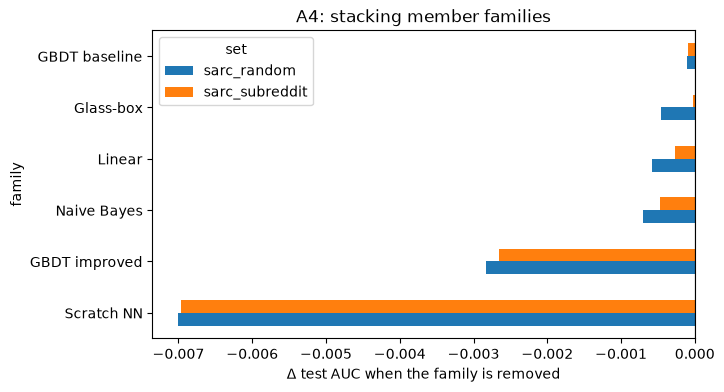

In [4]:
# Loss from removing each family
w = a4[a4.variant.str.startswith("without")].assign(family=lambda d: d.variant.str.replace("without ", ""))
p = w.pivot(index="family", columns="set", values="d_auc_vs_full").sort_values("sarc_random")
fig, ax = plt.subplots(figsize=(7, 4)); p.plot.barh(ax=ax)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Δ test AUC when the family is removed")
ax.set_title("A4: stacking member families"); U.savefig(fig, "S09_a4_members.png"); plt.show()

## A5 Stacking design

In [5]:
# Design variants on sarc_random
U.show(pd.read_csv(A / "a5_stacking_design.csv"))

,set,variant,val_auc_oof,test_auc,d_auc_vs_full,ci_low,ci_high,meta_rounds
0,sarc_random,"reference: calibrated logits, LR, cross-fitted",0.8374,0.8416,NaN,NaN,NaN,NaN
1,sarc_random,no calibration,0.8374,0.8416,-0.0000,-0.0000,0.0000,NaN
2,sarc_random,probability inputs instead of logits,0.8370,0.8411,-0.0005,-0.0006,-0.0003,NaN
3,sarc_random,"LightGBM meta-learner, no meta-features",0.8371,0.8414,-0.0002,-0.0004,0.0000,471.0
4,sarc_random,LightGBM meta-learner + meta-features,0.8373,0.8417,0.0001,-0.0002,0.0003,598.0
5,sarc_random,no cross-fitting (in-sample val AUC),0.8375,0.8416,0.0000,NaN,NaN,NaN


## A2 Text representation
The word + char LR from step 3 with one block removed at a time.

In [6]:
# Word, char and surface blocks
a2 = U.read_json(A / "a2_text_representation.json")
rows = [{"variant": k, "blocks": " + ".join(v["blocks"]), "features": v["n_features"], "val_auc": v["val_auc"],
         "test_auc": v["test"]["roc_auc"], "p75_recall": v["test"].get("p75_recall"),
         "d_vs_full": v.get("vs_full", {}).get("diff"), "ci_low": v.get("vs_full", {}).get("ci_low"),
         "ci_high": v.get("vs_full", {}).get("ci_high")} for k, v in a2.items()]
U.show(pd.DataFrame(rows))

,variant,blocks,features,val_auc,test_auc,p75_recall,d_vs_full,ci_low,ci_high
0,lr_word_surface,word + surface,299309,0.7984,0.8008,0.6897,-0.0176,-0.0187,-0.0167
1,lr_char_surface,char + surface,240271,0.7932,0.7981,0.6799,-0.0204,-0.0213,-0.0193
2,lr_word_char,word + char,539546,0.8121,0.8166,0.7248,-0.0018,-0.0021,-0.0015
3,lr_word_char_surface,word + char + surface,539563,0.8142,0.8184,0.7290,NaN,NaN,NaN


## Takeaways

- **A9:** no model loses AUC on authors never seen in training, so the results are not driven by author memorisation.
- **A4:** the from-scratch networks are the only family whose removal costs more than 0.003; improved GBDTs cost 0.003; every other family is below 0.001. Losses are the same on `sarc_subreddit`.
- **A5:** calibration, input scale, meta-learner type, meta-features and cross-fitting all change test AUC by at most 0.0005: the stack is robust to its design.
- **A2:** word and character n-grams are complementary: each alone gives about 0.80, together 0.8166; surface features add a further +0.0018.